In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

1. Генерация данных

In [16]:
# Настройка стиля графиков
sns.set(style="whitegrid")
np.random.seed(42) # Для воспроизводимости результатов

# a. N - 10 000
N = 10000

# b. X - равномерное распределение от 1 до 50
X = np.random.uniform(1, 50, N)

# c. E - нормальное распределение с центром 1 и отклонением в 10
# В numpy normal принимает (loc=среднее, scale=стандартное отклонение)
E = np.random.normal(loc=1, scale=10, size=N)

# d. Y = -3 + 0.5X + E
# Истинные коэффициенты: beta0 = -3, beta1 = 0.5
Y = -3 + 0.5 * X + E

# Создадим DataFrame для удобства
df = pd.DataFrame({'X': X, 'Y': Y})
print("Первые 5 строк данных:")
print(df.head())

Первые 5 строк данных:
           X          Y
0  19.352466  -7.202384
1  47.585001  10.540639
2  36.867703  20.322041
3  30.334266   1.428400
4   8.644913  13.448800


2. Нахождение уравнения линейной регрессии (MSE)

In [17]:
# Расчитываем суммы
sumX = np.sum(df.X)
sumY = np.sum(df.Y)
sumX2 = np.sum(df.X * df.X)
sumXY = np.sum(df.X * df.Y)
# Среднее
averX = np.average(df.X)
averY = np.average(df.Y)

# Получаем коэффициенты
beta1_pred = (N * sumXY - sumX * sumY) / (N * sumX2 - (sumX * sumX)) # Свободный член
beta0_pred = averY - beta1_pred * averX  # Коэффициент наклона

print(f"\nИстинные коэффициенты: beta0 = -3, beta1 = 0.5")
print(f"Найденные коэффициенты: beta0 = {beta0_pred:.4f}, beta1 = {beta1_pred:.4f}")


Истинные коэффициенты: beta0 = -3, beta1 = 0.5
Найденные коэффициенты: beta0 = -1.6742, beta1 = 0.4920


3. Построение графиков

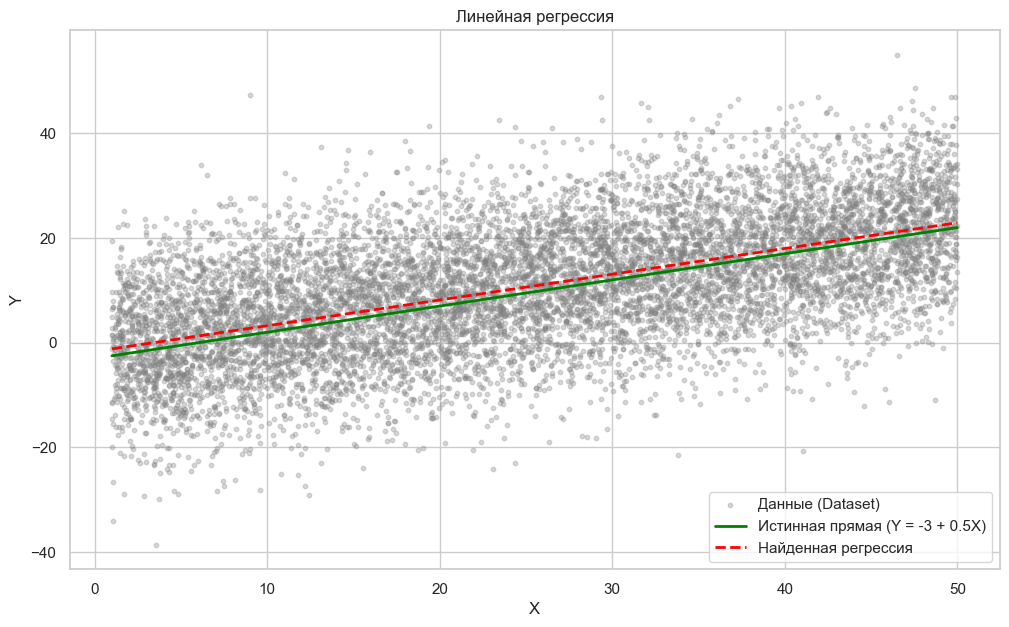

In [21]:
plt.figure(figsize=(12, 7))

# 4. Отображаем точки датасета (выборка, так как 10000 точек могут быть слишком плотными)
plt.scatter(X, Y, alpha=0.3, s=10, label='Данные (Dataset)', color='gray')

# Создаем массив X для построения линий
X_line = np.linspace(1, 50, 100)

# 5. Прямая согласно истинному выражению Y
Y_true_line = -3 + 0.5 * X_line
plt.plot(X_line, Y_true_line, color='green', linewidth=2, label='Истинная прямая (Y = -3 + 0.5X)')

# 4. Прямая согласно найденным коэффициентам
Y_pred_line = beta0_pred + beta1_pred * X_line
plt.plot(X_line, Y_pred_line, color='red', linestyle='--', linewidth=2, label='Найденная регрессия')

plt.title('Линейная регрессия')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

4. Метрики оценки качества

In [19]:
Y_pred = beta0_pred + beta1_pred * X
# a. MSE
mse = np.mean((Y - Y_pred) ** 2)
# b. R^2
ss_res = np.sum((Y - Y_pred) ** 2)
ss_tot = np.sum((Y - np.mean(Y)) ** 2)
r2 = 1 - (ss_res / ss_tot)
# c. MAPE
mape = np.mean(np.abs((Y - Y_pred) / Y)) * 100

print(f"\nМетрики качества:")
print(f"MSE: {mse:.4f}")
print(f"R^2: {r2:.4f}")
print(f"MAPE: {mape:.2f}")


Метрики качества:
MSE: 99.9321
R^2: 0.3248
MAPE: 250.97


5. Сравнение истинного и найденного решения

In [20]:
print("\n--- Сравнение решений ---")
print(f"Истинные параметры:  beta0 = -3.0000, beta1 = 0.5000")
print(f"Найденные параметры: beta0 = {beta0_pred:.4f}, beta1 = {beta1_pred:.4f}")
print(f"Разница (ошибка):    d_beta0 = {abs(-3 - beta0_pred):.4f}, d_beta1 = {abs(0.5 - beta1_pred):.4f}")

# Интерпретация:
# Так как E имеет мат. ожидание 1, а не 0, истинная линия регрессии смещена.
# Уравнение генерации: Y = -3 + 0.5X + E, где E ~ N(1, 10).
# Мат. ожидание Y: E[Y] = -3 + 0.5X + 1 = -2 + 0.5X.
# Следовательно, МНК должен найти beta0 около -2, а не -3.


--- Сравнение решений ---
Истинные параметры:  beta0 = -3.0000, beta1 = 0.5000
Найденные параметры: beta0 = -1.6742, beta1 = 0.4920
Разница (ошибка):    d_beta0 = 1.3258, d_beta1 = 0.0080
